<img src=https://courseware.decoded.com/images/decoded/logo-decoded.png align=left width=100px/>

# Time Series Analysis
---
<small>© COPYRIGHT 2026 DECODED LIMITED. ALL RIGHTS RESERVED. Web: https://decoded.com/ </small>


### Programmes

* Data Science Accelerator: Time Series Analysis and forecasting



### Learning Objectives
* Describe a time series as a composition between trends, seasonality and residuals
* Describe the core terminology of time series analysis esp., lag, stationarity, additive, multiplicative, ...
* Perform autocorrelation analysis
* Build and train a time series model
* Compare and contrast various approaches to time series analysis
* Use AutoGluon to train, compare and select time series forecasting models


## Content

### Overview

Diagnostics for time series forecasting
- Stationarity
- Challenge: Check for stationarity by eyeballing the time series graph
- ADF Test    
- Differencing
- Challenge: Re-run ACF and ADF test, is our differenced time series stationary?
- Challenge: Apply seasonal differencing with .diff(m) to reduce seasonality

Approaches to time series forecasting
- What approaches to Time Series forecasting are there?
- How do you evaluate a Time Series model?
- How do you build a Time Series model in python?
- Modelling with AutoARIMA
- Challenge: Report key parameters of a time series model and intepret them
- Challenge: Train and evaluate an SES model and compare the performance
- Challenge: Real-World Time Series Analysis

Machine learning in time series forecasting and evaluation methods
- What machine learning approaches to Time Series forecasting are there?
- How do you evaluate a Time Series model?
- How do you build a Time Series model in python?
- Modeling using tree methods
- Challenge: Report key parameters of a time series model and intepret them
- Challenge: Train and evaluate a random forest model and compare the performance
- Challenge: Train and evaluate a SARIMAX and compare the performance
- Challenge: Evaluation on time series machine learning algorithms

AutoML for time series forecasting
- Why use AutoML for model choice?
- Prepare time series data for AutoGluon
- Train several forecasting models automatically
- Compare models on a leaderboard
- Forecast the test period and evaluate with RMSE
- Decide whether AutoML improves on the baseline and manual models


### Introductions

#### Purpose: What is the aim of the content?

This workshop continues building on valuable skills for working with time-dependent data. You will get familiar with the core terminology, methods used and the components of a time series. You will also be introduced to how to build and train a time series forecasting model.

#### Applications: Why study time series analysis?

Analyzing historical data and identifying patterns and trends in time-dependent data can provide valuable insights and help make informed decisions in various fields.

For example, as a Data Scientist or Analyst, it can help you to build predictive models that can forecast future trends and outcomes, such as stock prices, weather patterns, sales figures etc., as a business professional it can help you gain insights into key business metrics such as revenue, customer acquisition, and churn rates, which can inform strategic decision-making.

Python has a range of libraries and tools that can automate much of the data cleaning, preprocessing, and modeling steps, making time series analysis faster and more efficient.

---

### What is Time Series analysis?

A time series is data which is recorded and observed over time where data points in a time series follow in sequential order due to the time variable, for example:

   - yearly GDP in the last 10 years in the UK
   - average daily temperatures in the northern hemisphere in the last 20 years
   - the weekly number of COVID-19 vaccines administered across the UK

Time series analysis involves analysing patterns in time series data in order to:

- Detect trends and/or seasonality
- Make predictions about the future (forecasting)
- Detect anomalies or change-points

etc.

### Importing required libraries

In [71]:
import pandas as pd
import matplotlib.pyplot as plt
import pmdarima as pm
import numpy as np
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import adfuller, acf
from statsmodels.tsa.holtwinters import SimpleExpSmoothing
from sklearn.metrics import mean_squared_error
import math
import random
import warnings
warnings.filterwarnings("ignore")

In [72]:
# set plotting configurations
plt.style.use('bmh')
plt.rcParams['figure.figsize']=(10,5)
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.rcParams['axes.xmargin'] = 0.
plt.rcParams['axes.ymargin'] = 0.
plt.rcParams.update({'font.size': 10})

In [73]:
# round the column to be displayed by integer
pd.options.display.float_format = '{:,.0f}'.format

Loading in the data as csv and setting the frequency,

In [74]:
ts = pd.read_csv('government_service_requests.csv')
ts.index=pd.date_range('2017-01-01', periods=len(ts), freq='W')
ts.head()
# drop the date column


,Unnamed: 0,unemployment_claim,retail_closure
2017-01-01,2017-01-01,"20,952",11
2017-01-08,2017-01-08,"19,525",10
2017-01-15,2017-01-15,"21,360",11
2017-01-22,2017-01-22,"23,685",13
2017-01-29,2017-01-29,"20,350",10


In [75]:
# Drop the unnecessary columns
ts.drop(columns=['Unnamed: 0'], inplace=True)


### Training time series models

#### Seasonal decomposition: what is happening in the data?

Decomposition helps us separate a time series into three useful parts:

- **Trend** — the overall direction over time.
- **Seasonality** — a pattern that repeats.
- **Residual** — the variation left over after trend and seasonality.

We use an **additive decomposition** in this exercise. You do not need to choose between decomposition types here — the goal is to spot the main patterns before we start forecasting.

Optional: You can try multiplicative decomposition as an alterative to spot patterns

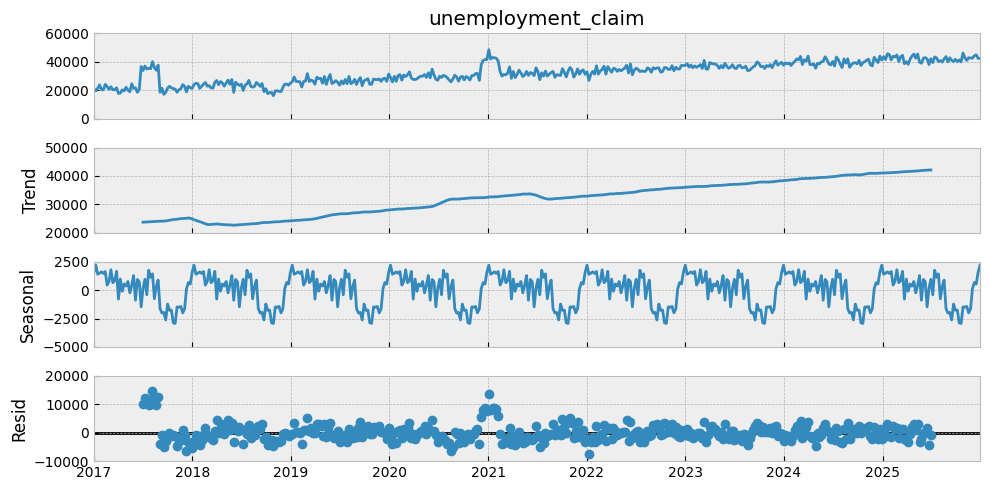

In [76]:
# seasonal decomposition
decomposition = seasonal_decompose(ts['unemployment_claim'], model='additive')
decomposition.plot()

plt.show()

#### Read the decomposition plot

Read the four charts from top to bottom:

1. **Observed** — the original time series.
2. **Trend** — the general direction.
3. **Seasonal** — the repeating pattern.
4. **Residual** — what the trend and seasonal pattern do not explain.

**Quick check**

- What is the overall direction of the series?
- Can you see a repeating pattern?
- Do the residuals look mostly pattern-free?

You are looking for useful patterns, not a perfect explanation of every movement.

Apply an additive decomposition by setting `model='a'`

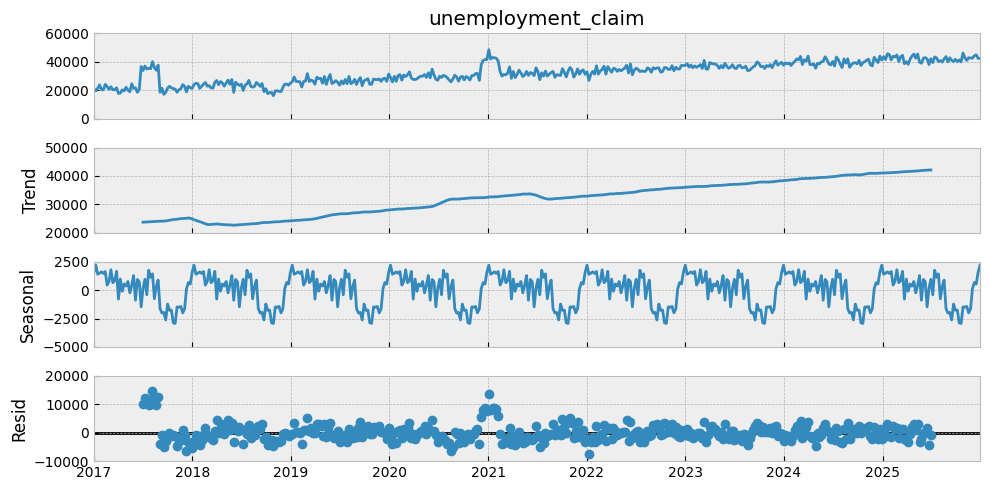

In [77]:
sdc_a = seasonal_decompose(ts['unemployment_claim'], model='a')
sdc_a.plot()
plt.show()

Extract and plot the denoised additive model to see how well an additive composition fits the data,

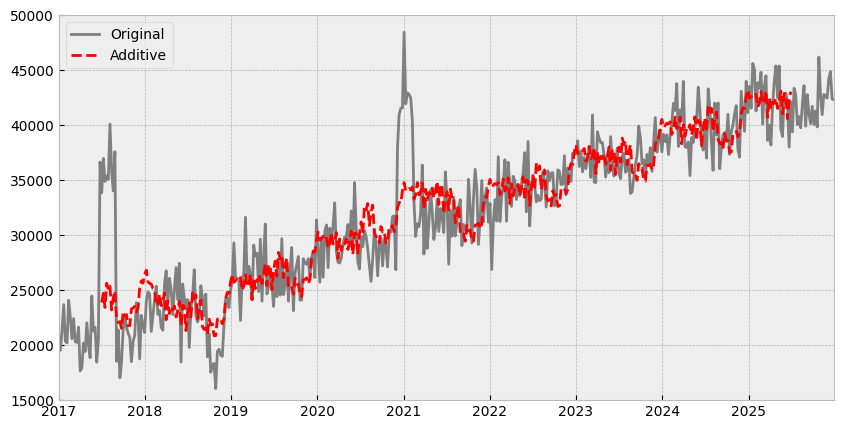

In [78]:
# This is the additive model, which is the sum of the trend and seasonal components. The residual component is not included in this model, as it represents the random noise in the data that cannot be explained by the trend and seasonality. By plotting the additive model against the original time series, we can visually assess how well the trend and seasonal components capture the underlying patterns in the data.
additive_model = sdc_a.trend + sdc_a.seasonal

# Plot the original time series and the additive model together to compare them. 
# The original time series is plotted in grey, while the additive model is plotted
plt.plot(ts['unemployment_claim'], label = 'Original', color='grey')
plt.plot(additive_model, label = 'Additive', linestyle='--', color='red')
plt.legend();

#### Challenge: Is an additive or multiplicative decomposition best suited for this data?

- Apply a multiplicative decomposition by setting `model='m'`
- Extract the denoised multiplicative model by modifying `additive_model` and renaming to `multiplicative_model`
- Plot the denoised multiplicative model alongside the original time series
- Compare to the results of the additive decomposition, which best describes this data?

Note: If the variance of the residuals changes quite dramatically over time (known as heteroscedasticity) or shows a pattern, this suggests that the decomposition is not suitable for the data.

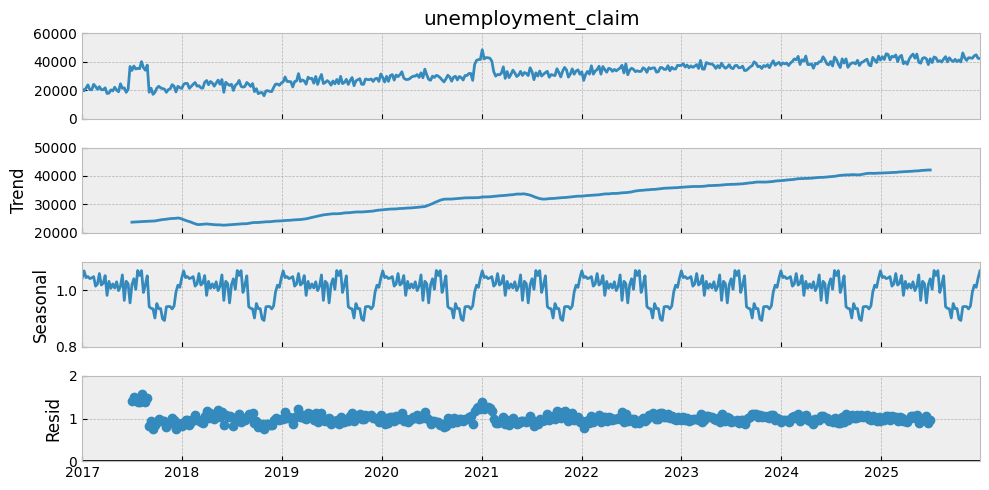

In [79]:
## multiplicative model
sdc_m = seasonal_decompose(ts['unemployment_claim'], model='m')
sdc_m.plot()
plt.show()
# What parameter should we use for the period in the multiplicative model?


Extract and plot the denoised multiplicative model to see how well an multiplicative composition fits the data,

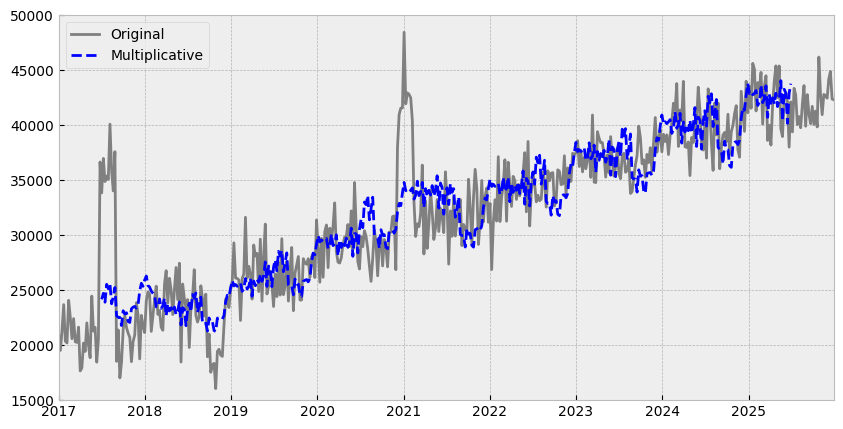

In [80]:
##
# What should be the sign here for the multiplicative model?
# what should we do to the trend and seasonal components for the multiplicative model?
multiplicative_model = sdc_m.trend * sdc_m.seasonal

# Plot the original time series and the multiplicative model together to compare them. 
# The original time series is plotted in grey, while the multiplicative model is plotted
plt.plot(ts['unemployment_claim'], label = 'Original', color='grey')
plt.plot(multiplicative_model, label = 'Multiplicative', linestyle='--', color='blue')
plt.legend();

# How should we plot the multiplicative model against the original time series?


You could practise in your own time by accessing this link:

https://kourentzes.com/forecasting/2014/11/09/additive-and-multiplicative-seasonality/

### Testing for stationarity

Next, we check whether the series is reasonably stable over time.

A stationary series has no strong long-term change in its average level or its spread.

We will check this in three ways:

- Look at the graph
- Look at the ACF plot
- Run the ADF test

Use these checks together rather than relying on one result.

#### Challenge: Check for stationarity by eyeballing the time series graph

Let's plot the level of the series with a rolling window. Do you observe signs of non-stationarity?

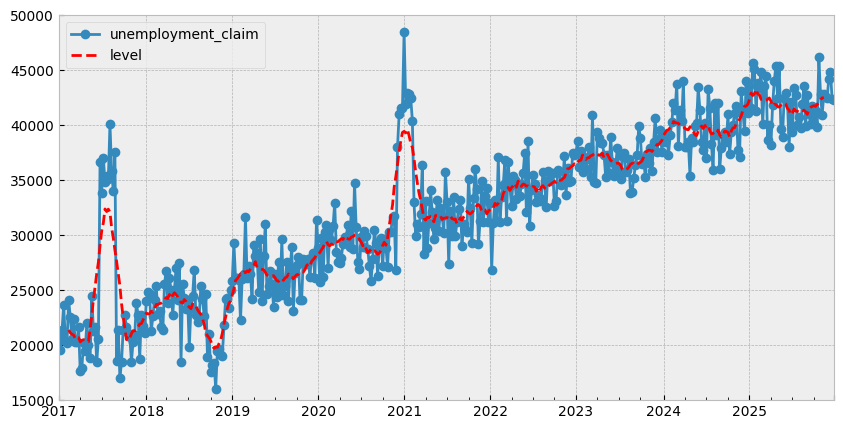

In [81]:
ts['unemployment_claim'].plot(marker='o');
# we can use rolling mean to estimate the level of the time series, which is the underlying trend without seasonality and noise. 
# We can use a window size of 13 to capture the yearly seasonality in the data.
level = ts['unemployment_claim'].rolling(window=13, center=True).mean()
level.plot(linestyle='--',label='level', color='red');
plt.legend();

#### Check for stationarity using `plot_acf()` from `statsmodels`

We can spot the presence of a trend through the slowly decaying correlation coefficients, therefore it is likely our time series is non-stationary.


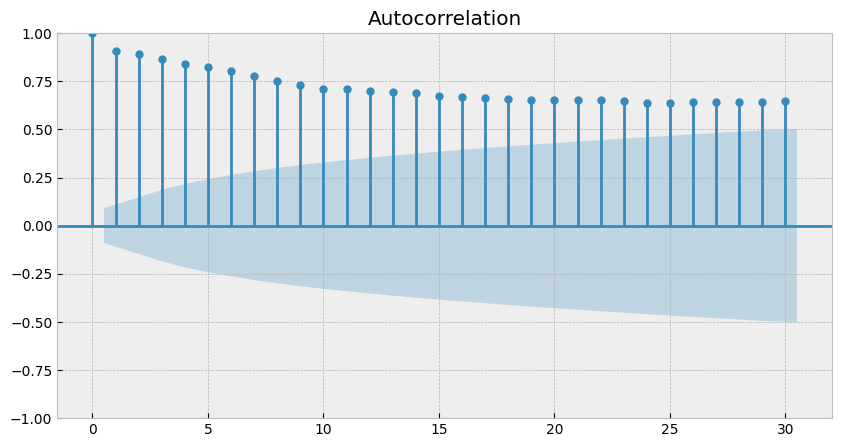

In [82]:
plot_acf(ts['unemployment_claim'], lags=30); # Try changing the number of lags to see how it affects the plot

#### Stretch: Augmented Dickey-Fuller (ADF) test for stationarity


There are different types of statistical tests you can perform to test for stationarity, the most common ones fall under the category of unit root tests.

We will not dive into the specifics of unit root tests so it is suffice to say that they look for a very specific type of stationarity (the presence of a unit root) but there might be other types that can go undetected by these tests: for example, if a series has strong seasonality.

Despite this, they still provide a good starting point. They do detect the presence of a trend in the data, which is a type of non-stationarity. But we will also have to check for the presence of seasonality once the trend has been removed, to conclude that the series is stationary.

The ADF (Augmented Dickey-Fuller test), is a type of statistical test based on unit roots. The null and alternative hypotheses are as follows:

* H0: The series has a unit root and it **is NOT stationary**.
* H1: The series does not have a unit root and it **is stationary**.

Run an Augmented Dickey-Fuller (ADF) test for stationarity using  `adfuller()`

In [83]:
p_value_adf = adfuller(ts['unemployment_claim'])[1]

print(f'ADF Test p-value: {p_value_adf:.4f}')

ADF Test p-value: 0.4564


Looking through the documentation we can see that the `p-value` is the second item (index 1) in the output.

Therefore the p value is significantly less than  than 0.05, and therefore we can reject the null hypothesis, that the series has a unit root and it is NOT stationary.

#### Differencing a time series

We can stablise the mean of a time series through differencing `.diff()` and/or seasonal differencing `.diff(m)` to help make our time series stationary.

ARIMA models have a hyperparameter for differencing, it is important for us as analysts and programmers to determine what the hyperparameter `d` (differencing to reduce the trend) and `D` (differencing to reduce seasonality) should be.

##### Differencing to reduce trend using `.diff()`

Differencing entails subtracting consecutive observations of a time series.

If the increase in mean for each period is roughly constant (in other words, there is a linear trend), the trend would be mostly eliminated by first order differencing. 

We can apply first order differencing in Python using `.diff()`.

```python
firstdiff = ts.diff()
```

If the trend is quadratic, or non-linear, differencing once may not be enough to reduce the trend. You may need to perform second order differencing.

```python
seconddiff = ts.diff().diff()
```

We can apply second order differencing in Python using `.diff().diff()`. Higher order differencing is possible but rarely needed.

##### Seasonal differencing to reduce seasonality using `.diff(m)`

Seasonal differencing entails subtracting consecutive seasonal observations of a time series.

First order differencing seasonal differencing is as follows:

```python
first_seasonal_diff = ts.diff(m)
```

Seasonal differencing once may not be enough to reduce the seasonality. You may need to perform second order seasonal differencing.

We can apply second order seasonal differencing in Python using `.diff(m).diff(m)`.

```python
second_seasonal_diff = ts.diff(m).diff(m)
```

Higher order seasonal differencing is also possible but is rarely needed.

#### Differencing with `.diff()` to reduce the trend

A way of removing/reducing trend in a time series is by differencing. Usually differencing once with `.diff()` is enough to make a time series stationary but we may need to apply second order differencing `.diff().diff()` or higher order differencing.

<Axes: >

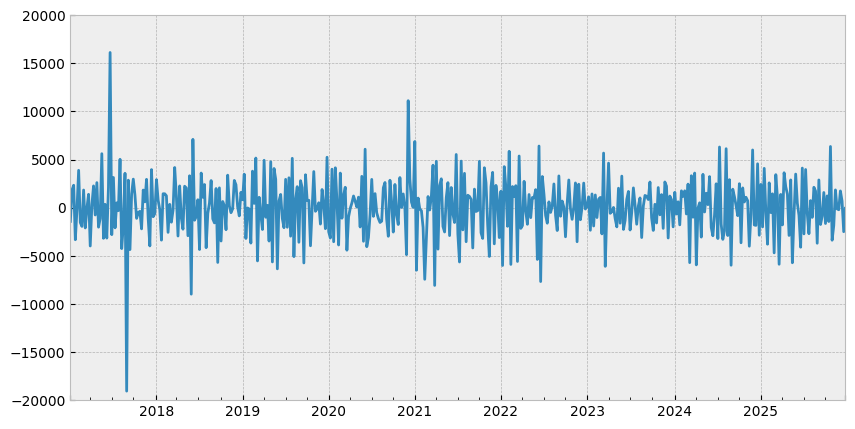

In [84]:
ts_diff = ts['unemployment_claim'].diff().dropna() # Why do we need to drop NaN values here?

# Create a plot
ts_diff.plot()

#### Challenge: Re-run `ACF` and `ADF` test, is our differenced time series stationary?

- Run the ADF test again to check for stationarity.
- The ADF test does not check for seasonality, so run an ACF plot again to check for seasonality.
- Jot down any results and observations.

Run the ADF test again to check for stationarity,

In [85]:
# SOLUTION (NOTES)
p_value_adf_diff = adfuller(ts_diff)[1]

print(f'ADF Test p-value: {p_value_adf_diff:.4f}')

ADF Test p-value: 0.0000


### Time series forecasting - training the model

Here's a brief overview of each of these time series forecasting methods:

1. **Exponential Smoothing Models**: used for forecasting time series data by applying weighted averages of past time points where the weights decrease exponentially over time.

2. **Moving Average Models**: forecast future values based on the average of past data points.

3. **Autoregressive Models**: forecast future values of a time series using a linear combination of its own previous values.

4. **Box-Jenkins Models**: The Box-Jenkins methodology, also known as ARIMA (Autoregressive Integrated Moving Average), is a sophisticated approach that combines autoregressive models, moving averages, and differencing to make a non-stationary time series stationary. The model is versatile and can handle a variety of time series patterns, making it one of the most commonly used forecasting methods.

5. **Deep Learning Models**: Deep learning models, are also popular, these models are capable of capturing complex patterns in large volumes of data, handling nonlinear relationships, and considering long-term dependencies in the data.

6. **Tree-Based Models**: Tree-based models, such as Random Forest and XGBoost, can be adapted for time series forecasting by transforming the time series into a supervised learning problem using lagged features. These models are capable of capturing nonlinear relationships and interactions between features, making them suitable for complex time series data.

Each of these methods has its strengths and is suitable for different types of time series data and forecasting requirements.

### How do you forecast and evaluate a Time Series model?

There are several metrics to evaluate how informative and accurate a time series model is, such as:

- Forecast error

    - for every time period `t` in our dataset we take the difference between actual values and fitted values (values that we estimate using our model for the same time periods).

- Mean absolute error (MAE)

    - This metric involves taking the average of the absolute values of forecast errors at each period `t`, capturing the magnitude of the error (in other words how spread out the values are) rather than the direction of this effect (whether the error is positive or negative). It will also avoid errors of opposite signs cancelling each other out.

- Mean squared error (MSE)

    - The difference between the MSE and the previous metric (MAE) is that, instead of taking the absolute value of errors at each time period `t` and averaging them, we are now squaring the differences, this will more greatly penalise larger errors.

- Root mean square error (RMSE)

    - The square root of the MSE, this brings the MSE back to the same scale as the raw data.

- Mean absolute percentage error (MAPE)

    - A scale-independent metric, which means that error sizes are not sensitive to the scale of the series, however, this metric can be unstable.

The choice of error metric to use when evaluating your model depends entirely on the use case.

### How do you build a Time Series model in python?

#### Train-test split for time series

We need to split our data into a train set to fit the model, and a test set that will be unseen by the model, usually the last 10-30% observations in the dataset (depending on its size) to evaluate our predictions.

Because we are working with chronologically ordered time series data, we cannot use the usual `train_test_split` function in `sklearn` as it relies on random sampling. Instead, we generally use the first 70-90% of observations in our dataset as a train set, and the remainder as test set.

Performing this type of train/test split in Python is as simple as choosing the number of observations we want to use for the test set and then using standard slicing notation.

Split the data with the first 80% of data points in the training set and the final 20% in the test set,

In [86]:
threshold = int(len(ts) * 0.8)
# split the data into training and test sets
train = ts['unemployment_claim'][:threshold] # What should be the sign here for the training set?
test = ts['unemployment_claim'][threshold:] # What should be the sign here for the testing set


#### Building a baseline time series model

First, it is good practice to establish a baseline model so that we have something to compare our model performances to.

For our baseline model we will use the Persistence Algorithm (the “naive” forecast).

This uses the previous value in the series to predict the expected outcome of the next value in the time series.

Generate the naive forecasts with `.shift()`

In [87]:
# generate the naive predictions, which is the value of the previous time step

ts['naive_pred'] = ts['unemployment_claim'].shift(1)



In [88]:
ts.tail()

,unemployment_claim,retail_closure,naive_pred
2025-11-30,"42,449",10,"42,670"
2025-12-07,"44,184",11,"42,449"
2025-12-14,"44,875",12,"44,184"
2025-12-21,"42,376",9,"44,875"
2025-12-28,"42,310",9,"42,376"


Plot the naive forecasts for the test set,

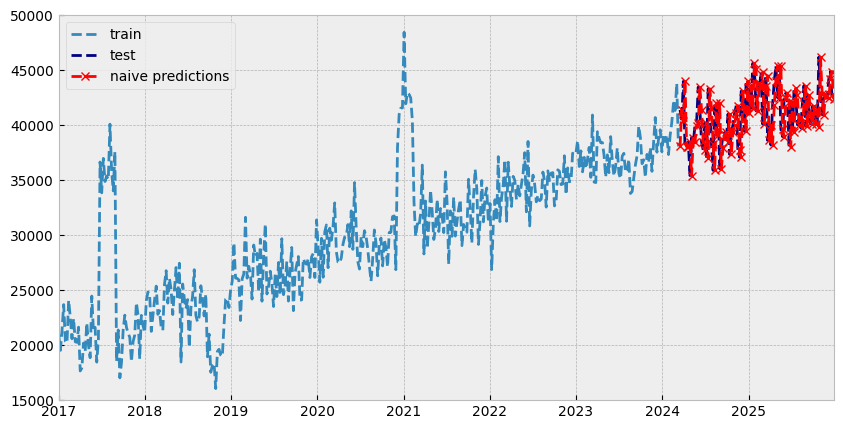

In [89]:
plt.plot(train, label="train", linestyle='--')
plt.plot(test, label="test", color="navy", linestyle='--')

plt.plot(ts['naive_pred'][threshold:], label="naive predictions", marker = 'x', linestyle='--', color='red')

plt.legend(loc='upper left');

To measure performance, we can use the RMSE evaluation metric by first calculating the MSE score using `mean_squared_error()` from `sklearn` and then taking the square root using `sqrt()` from `math` as follows,

In [90]:
# calculate the test score using root mean squared error (RMSE)
test_score_naive = math.sqrt(mean_squared_error(test, ts['naive_pred'][threshold:]))
test_score_naive

2875.8564403237788

We get an RMSE score and we use this to check if our machine learning forecasting models are doing their job correctly.

We will know whether they are performing better than the baseline model if they can achieve a lower RMSE score than the baseline model.

The goal is to to minimise this score.

#### Modelling with `AutoARIMA`

We can use `AutoARIMA` from `pmdarima` which will automatically determine the best hyperparameter values `(p,d,q)(P,D,Q)m`, where,

- p is the order (number of lags) incorporated into our model
- d is the degree of differencing (the number of times the data have had past values subtracted)
- q is the number of past error terms incorporated into our model
- P is the number of seasonal lags incorporated into our model
- D is the degree of seasonal differencing
- Q is the number of past seasonal error terms incorporated into our model
- m is the seasonal period

As analysts and programmers, it is good practice to determine and set `d` and `D` ourselves, as sometimes the model struggles to test and converge for these values. We should also provide a range of `p` and `q` to narrow the search space as follows,

In [91]:
autoarima_model = pm.arima.AutoARIMA(start_p=0 ,max_p=2, d=1, start_q=0, max_q=2,
                                     start_P=0, max_P=1, D=0, start_Q=0, max_Q=1, m=12)

autoarima_model.fit(train)

,start_p,0
,d,1
,start_q,0
,max_p,2
,max_d,2
,max_q,2
,start_P,0
,D,0
,start_Q,0
,max_P,1
,max_D,1


We can look at a summary of the model generated by `AutoARIMA` using `.summary()`

In [92]:
autoarima_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                      y   No. Observations:                  376
Model:               SARIMAX(0, 1, 1)   Log Likelihood               -3510.289
Date:                Tue, 11 Aug 2026   AIC                           7024.578
Time:                        14:48:28   BIC                           7032.432
Sample:                    01-01-2017   HQIC                          7027.696
                         - 03-10-2024                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.4490      0.033    -13.445      0.000      -0.514      -0.384
sigma2      7.859e+06   2.71e+05     29.050      0.000    7.33e+06    8.39e+06
===================================================================================
Ljung-Box (L1) (Q):                   0.85   Jarque-Bera (JB):               766.52
Prob(Q):                              0.36   Prob(JB):                         0.00
Heteroskedasticity (H):               0.40   Skew:                            -0.28
Prob(H) (two-sided):                  0.00   Kurtosis:                         9.98
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

Generate and plot the predictions made by the `AutoArima` model,

In [93]:
# Create the prediction and confidence intervals for the test set using the fitted model

prediction, confint = autoarima_model.predict(n_periods=test.shape[0], return_conf_int=True)
autoarima_preds = pd.Series(prediction, index=test.index)
cf = pd.DataFrame(confint)


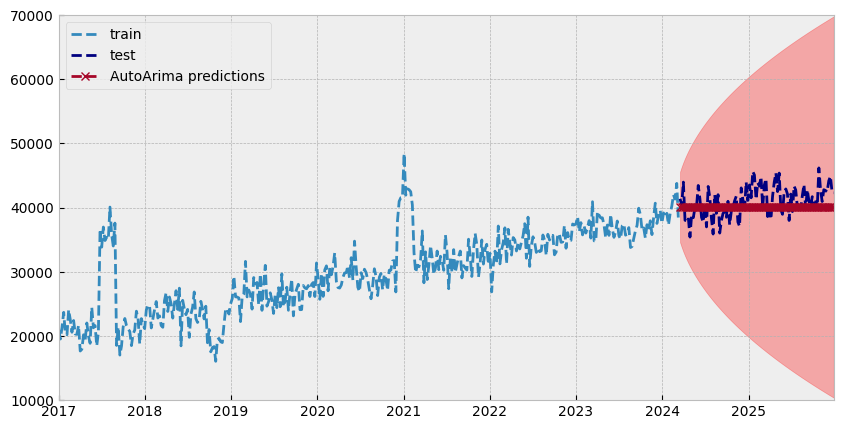

In [94]:
# Create the plot to visualise the predictions and confidence intervals
# 
plt.plot(train, label="train", linestyle='--')
plt.plot(test, label="test", color="navy", linestyle='--')

# What does this line of code do? What are the parameters used for?
plt.plot(autoarima_preds, label="AutoArima predictions", marker = 'x', linestyle='--')

# What should we do to the confidence intervals to visualise them in the plot?
plt.fill_between(test.index, cf[0], cf[1], alpha=.3, color='red') 


plt.legend(loc='upper left');

Use RMSE evaluation metric by using `mean_squared_error()` from `sklearn` and `sqrt()` from `math` to measure performance

In [95]:
test_score_autoarima = math.sqrt(mean_squared_error(test, autoarima_preds))
test_score_autoarima

2585.960758281761

Compare the RMSE scores. what does it tell?

Therefore, we know our machine learning `AutoArima`	forecasting model is performing much better than the baseline model.

#### Challenge: Report key parameters of a time series model and intepret them

What hyperparameter values were outputted from `AutoArima` and are they the best choice based on our analysis?

- p=
- d=
- q=

- P=
- D=
- Q=

- m=

<hr /> <div style='page-break-after: always; display: none'>\pagebreak</div>

### Tree-Based Time Series Forecasting

Tree-based models like Random Forest and XGBoost can be used for time series forecasting by creating lagged features from the time series data. This transforms the forecasting problem into a supervised learning regression task.

#### Feature Engineering for Time Series
To apply tree-based models, we create features such as:
- Lagged values (e.g., value at t-1, t-2, etc.)
- Rolling statistics (e.g., moving averages)
- Seasonal indicators
- Other exogeneous indicators
- A mixture of the above


#### Implementation in Python

In [96]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor , GradientBoostingRegressor

from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

In [97]:
# Load the copied time series data
data = ts


In [98]:
# Create lagged 1 and 2 as features 
# fill in the lag1
data['claim_lag1'] = data['unemployment_claim'].shift(1)
data['claim_lag2'] = data['unemployment_claim'].shift(2)
data['moving_avg_13'] = data['unemployment_claim'].rolling(window=13).mean()
data['retail_closure_lag1'] = data['retail_closure'].shift(1)
# create 13 week moving average as another feature

#### Split the feature and target time series

In [99]:

data = data.dropna()

# use lagged features variable to create the train test set
X = data.drop('unemployment_claim', axis=1)
y = data['unemployment_claim']

### Train test split

In [100]:

# Train-test split (use last 26 weeks for testing)
train_size = threshold
#
# How do we split the data into train and test sets for time series forecasting?
# We need to make sure that the training set contains only data from before the test set, to avoid data leakage.
X_train, X_test = X[:train_size], X[train_size:]
# how do we split the target variable?

y_train, y_test = y[:train_size], y[train_size:]

In [101]:
# Train Random Forest model
rf_model = RandomForestRegressor(n_estimators=20, random_state=42)
rf_model.fit(X_train, y_train)


,n_estimators,20
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


#### Challenge: Calculate the performance using training and test data

* Like regression models, we need to calculate performance metrics on our training data
* Display the RMSE, MSE and MAE for the training data set

In [102]:
# Make predictions on the training set and calculate the MSE, MAE, and RMSE
rf_predictions_train = rf_model.predict(X_train)
# Calculate metrics on training set
rf_mse_train = mean_squared_error(y_train, rf_predictions_train)
rf_mae_train = mean_absolute_error(y_train, rf_predictions_train)
rf_rmse_train = np.sqrt(rf_mse_train)   


# Make predictions for the test set
rf_predictions_test = rf_model.predict(X_test)
# Calculate metrics
rf_mse_test = mean_squared_error(y_test, rf_predictions_test)
rf_mae_test = mean_absolute_error(y_test, rf_predictions_test)
rf_rmse_test = np.sqrt(rf_mse_test)

# Display the results for the training and test sets
print(f"Random Forest - Train MSE: {rf_mse_train:.2f}, Train MAE: {rf_mae_train:.2f}, Train RMSE: {rf_rmse_train:.2f}")
print(f"Random Forest - Test MSE: {rf_mse_test:.2f}, Test MAE: {rf_mae_test:.2f}, Test RMSE: {rf_rmse_test:.2f}")



Random Forest - Train MSE: 408845.50, Train MAE: 380.34, Train RMSE: 639.41
Random Forest - Test MSE: 6051340.90, Test MAE: 2130.46, Test RMSE: 2459.95


* What do we observe from the RMSE here ? Better or worse than ARIMA and seasonal?

### Let's train another model - Gradient Boosting Regressor

In [103]:
# Train Gradient Boosting model
gradient_model = GradientBoostingRegressor(n_estimators=20, random_state=42)
gradient_model.fit(X_train, y_train)

,loss,'squared_error'
,learning_rate,0.1
,n_estimators,20
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


#### Challenge: Evaluate the performance using training data and test data

* Like regression models, we need to calculate performance metrics on our training data
* Display the RMSE, MSE and MAE for the training data set
* How does Gradient Boosting regressor compare to other model in terms of performance?

In [104]:
# Make predictions on the training set and calculate the MSE, MAE, and RMSE
gradient_model_predictions_train = gradient_model.predict(X_train)
# Calculate metrics on training set
gradient_model_mse_train = mean_squared_error(y_train, gradient_model_predictions_train)
gradient_model_mae_train = mean_absolute_error(y_train, gradient_model_predictions_train)
gradient_model_rmse_train = np.sqrt(gradient_model_mse_train)   

# Make predictions for the test set
gradient_model_predictions_test = gradient_model.predict(X_test)
# Calculate metrics
gradient_model_mse_test = mean_squared_error(y_test, gradient_model_predictions_test)
gradient_model_mae_test = mean_absolute_error(y_test, gradient_model_predictions_test)
gradient_model_rmse_test = np.sqrt(gradient_model_mse_test)
# Display the results for the training and test sets
print(f"Gradient Boosting - Train MSE: {gradient_model_mse_train:.2f}, Train MAE: {gradient_model_mae_train:.2f}, Train RMSE: {gradient_model_rmse_train:.2f}")
print(f"Gradient Boosting - Test MSE: {gradient_model_mse_test:.2f}, Test MAE: {gradient_model_mae_test:.2f}, Test RMSE: {gradient_model_rmse_test:.2f}")



Gradient Boosting - Train MSE: 2437023.78, Train MAE: 1201.47, Train RMSE: 1561.10
Gradient Boosting - Test MSE: 21273765.84, Test MAE: 4411.12, Test RMSE: 4612.35


#### Visualise the results

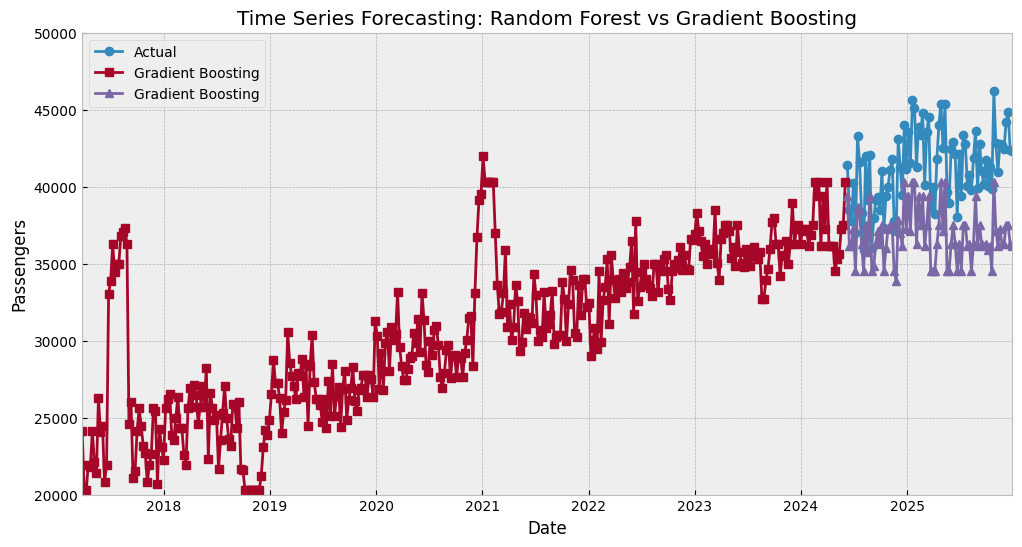

In [105]:
# Plot the results
plt.figure(figsize=(12, 6))
plt.plot(y_test.index, y_test.values, label='Actual', marker='o')
# plot the predictions for the training and test sets for both models
plt.plot(y_train.index, gradient_model_predictions_train, label='Gradient Boosting', marker='s')
plt.plot(y_test.index, gradient_model_predictions_test, label='Gradient Boosting', marker='^')
plt.title('Time Series Forecasting: Random Forest vs Gradient Boosting')
plt.xlabel('Date')
plt.ylabel('Passengers')
plt.legend()
plt.show()


####

### Create a table to show the performance of all models

In [106]:
# Put a table comparing the performance of all the models we have trained so far, including the naive forecast, SES, AutoARIMA, SARIMAX, Random Forest, and XGBoost. The table should include the RMSE for each model.
performance_data = {
    'Model': ['Naive Forecast',  'AutoARIMA', 'Random Forest', 'Gradient Boosting'],
    'RMSE': [test_score_naive, test_score_autoarima, rf_rmse_train, gradient_model_rmse_train]
}
performance_df = pd.DataFrame(performance_data)
print(performance_df)

               Model  RMSE
0     Naive Forecast 2,876
1          AutoARIMA 2,586
2      Random Forest   639
3  Gradient Boosting 1,561


#### Performance Comparison
Tree-based models offer several advantages for time series forecasting:
- **Handling Nonlinearity**: They can capture complex nonlinear patterns in the data.
- **Feature Interactions**: Automatically model interactions between lagged features.
- **Robustness**: Less sensitive to outliers compared to linear models.
- **Interpretability**: Feature importance can provide insights into which lags are most predictive.

However, they may require more computational resources and careful hyperparameter tuning. In this example, we compared Random Forest and XGBoost on the air passengers dataset. The choice between them depends on the specific dataset and computational constraints.

## Optional stretch

### AutoML for time series: choosing between multiple models with AutoGluon

So far, we have chosen and trained forecasting models ourselves. That is useful because it helps us understand what each model is doing.

In real data science work, we may also want to compare several sensible models quickly. **AutoML** helps automate parts of this model-selection process.

For time series, AutoGluon can train several forecasting approaches, score them on validation data and rank them on a leaderboard. We still make the final decision: AutoML speeds up the comparison, but it does not replace data understanding, good evaluation or judgement.

**Our workflow:**
1. Define the forecasting problem and evaluation metric.
2. Keep the final time period unseen as test data.
3. Put the data into AutoGluon's time series format.
4. Train multiple models automatically.
5. Compare models on the leaderboard.
6. Use the selected model to forecast the test period.
7. Evaluate the forecast against the unseen actual values.
8. Compare the result with our baseline and manually trained models.


#### Step 1: Import AutoGluon

We only need two AutoGluon classes:

- `TimeSeriesDataFrame` stores time series data in the format AutoGluon expects.
- `TimeSeriesPredictor` trains, compares, selects and uses forecasting models.

> If the import fails on your local computer, check that `autogluon` is installed in the same Jupyter environment as this notebook.


In [107]:
from autogluon.timeseries import TimeSeriesDataFrame, TimeSeriesPredictor


#### Step 2: Prepare the time series

AutoGluon expects a timestamp, a target and an `item_id`. The `item_id` tells AutoGluon which observations belong to the same time series.

Here we have one weekly series: `unemployment_claim`. We create one item ID for the whole series.


In [108]:
# Start from the original target series only
ag_df = ts[['unemployment_claim']].copy().reset_index()
ag_df = ag_df.rename(columns={'index': 'timestamp'})
ag_df['item_id'] = 'unemployment_claim_series'

# Keep only the columns AutoGluon needs for this example
ag_df = ag_df[['item_id', 'timestamp', 'unemployment_claim']]
ag_df.head()


,item_id,timestamp,unemployment_claim
0,unemployment_claim_series,2017-01-01,"20,952"
1,unemployment_claim_series,2017-01-08,"19,525"
2,unemployment_claim_series,2017-01-15,"21,360"
3,unemployment_claim_series,2017-01-22,"23,685"
4,unemployment_claim_series,2017-01-29,"20,350"


#### Step 3: Keep the final period unseen

We use the same forecasting idea as before: train on the past and test on the most recent observations.

`prediction_length` is how many future weekly values we want the model to forecast. We use the same number of observations as our existing test set so that the model comparison is fair.


In [109]:
prediction_length = len(test)

ag_train_df = ag_df.iloc[:-prediction_length].copy()

ag_train = TimeSeriesDataFrame.from_data_frame(
    ag_train_df,
    id_column='item_id',
    timestamp_column='timestamp'
)

ag_full = TimeSeriesDataFrame.from_data_frame(
    ag_df,
    id_column='item_id',
    timestamp_column='timestamp'
)

print(f'Training observations: {len(ag_train_df)}')
print(f'Forecast horizon: {prediction_length} weeks')


Training observations: 376
Forecast horizon: 94 weeks


#### Step 4: Train multiple forecasting models automatically

We use RMSE because that is the metric we have used elsewhere in this workbook.

The `fast_training` preset keeps this classroom example manageable. AutoGluon will try a selection of fast baseline, statistical and tree-based forecasting models, then rank the trained models using validation performance.

In a real project, you could allow more training time or test a higher-quality preset after you have a working baseline.


In [110]:
ag_predictor = TimeSeriesPredictor(
    prediction_length=prediction_length,
    target='unemployment_claim',
    eval_metric='RMSE'
)

ag_predictor.fit(
    ag_train,
    presets='fast_training',
    time_limit=120
)


Beginning AutoGluon training... Time limit = 120s
AutoGluon will save models to '/Users/james.lam/Workshops/Data Science Accelerator/Time Series/AutogluonModels/ag-20260811_134828'
=================== System Info ===================
AutoGluon Version:  1.5.0
Python Version:     3.11.15
Operating System:   Darwin
Platform Machine:   arm64
Platform Version:   Darwin Kernel Version 24.6.0: Tue Jul 21 20:50:11 PDT 2026; root:xnu-11417.140.69.711.44~1/RELEASE_ARM64_T6041
CPU Count:          12
Pytorch Version:    2.9.1
CUDA Version:       CUDA is not available
GPU Count:          WARNING: Exception was raised when calculating GPU count (AssertionError)
Memory Avail:       4.87 GB / 24.00 GB (20.3%)
Disk Space Avail:   246.12 GB / 460.43 GB (53.5%)
Setting presets to: fast_training

Fitting with arguments:
{'enable_ensemble': True,
 'eval_metric': RMSE,
 'hyperparameters': 'very_light',
 'known_covariates_names': [],
 'num_val_windows': 1,
 'prediction_length': 94,
 'quantile_levels': [0.1, 

#### Step 5: Compare the models

The leaderboard shows the models AutoGluon trained and how they performed.

Look for:
- which model is ranked first;
- whether several models have similar scores;
- how long the models took to fit and predict;
- whether the best validation model also performs well on unseen test data.

AutoGluon displays leaderboard scores in a **higher-is-better** direction. For error metrics such as RMSE, this means the displayed score can be negative. A score closer to zero is better.


In [111]:
ag_leaderboard = ag_predictor.leaderboard(ag_full)
ag_leaderboard


Additional data provided, testing on additional data. Resulting leaderboard will be sorted according to test score (`score_test`).


,model,score_test,score_val,pred_time_test,pred_time_val,fit_time_marginal,fit_order
0,Theta,"-2,235","-1,977",2,1,0,6
1,WeightedEnsemble,"-2,255","-1,807",2,3,0,7
2,ETS,"-2,554","-2,795",0,2,0,5
3,SeasonalNaive,"-3,828","-2,469",1,1,0,2
4,Naive,"-3,828","-2,469",1,2,0,1
5,RecursiveTabular,"-9,573","-11,255",0,0,1,3
6,DirectTabular,"-12,935","-10,353",0,0,1,4


#### Step 6: Forecast the unseen test period

Now we ask the fitted AutoGluon predictor to forecast the next `prediction_length` weeks from the end of the training data.


In [112]:
ag_forecast = ag_predictor.predict(ag_train)

# Extract the mean forecast for our single time series
ag_predictions = (
    ag_forecast
    .xs('unemployment_claim_series', level='item_id')['mean']
)

ag_predictions.head()


Model not specified in predict, will default to the model with the best validation score: WeightedEnsemble


timestamp
2024-03-17   39,878
2024-03-24   39,982
2024-03-31   39,907
2024-04-07   40,000
2024-04-14   39,940
Name: mean, dtype: float64

#### Step 7: Evaluate the forecast with RMSE

We compare the AutoGluon forecast with the actual values in the unseen test period. Lower RMSE is better.


In [113]:
# Align the forecast and actual values by time
ag_actual = ts.loc[ag_predictions.index, 'unemployment_claim']

autogluon_rmse = np.sqrt(mean_squared_error(ag_actual, ag_predictions))
print(f'AutoGluon RMSE: {autogluon_rmse:.2f}')


AutoGluon RMSE: 2255.44


#### Step 8: Visualise the forecast

A metric gives us one summary number. A plot helps us see **where** the forecast follows the pattern well and where it misses important changes.


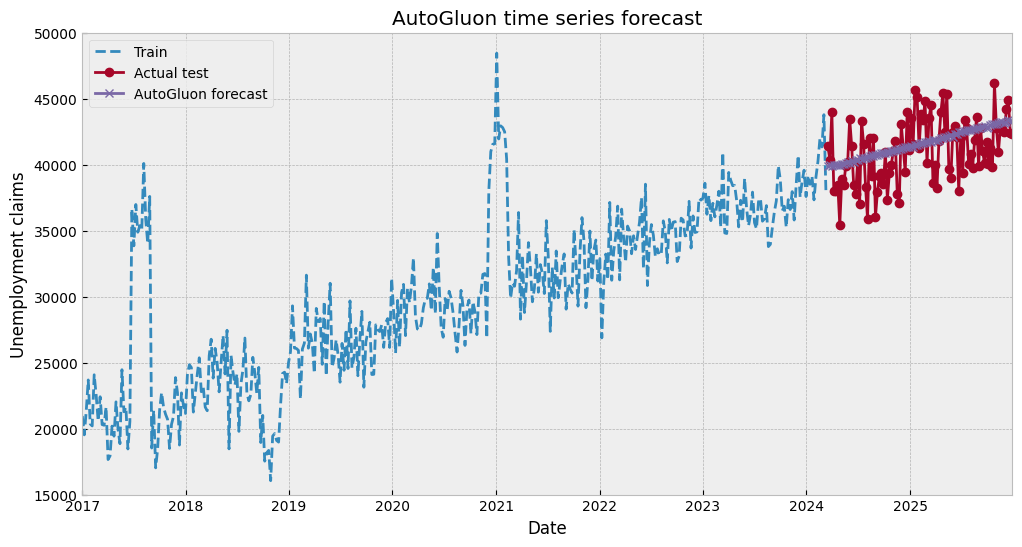

In [114]:
plt.figure(figsize=(12, 6))
plt.plot(train.index, train.values, label='Train', linestyle='--')
plt.plot(ag_actual.index, ag_actual.values, label='Actual test', marker='o')
plt.plot(ag_predictions.index, ag_predictions.values, label='AutoGluon forecast', marker='x')
plt.title('AutoGluon time series forecast')
plt.xlabel('Date')
plt.ylabel('Unemployment claims')
plt.legend()
plt.show()


#### Step 9: Compare AutoGluon with the models we trained ourselves

AutoML is useful when it helps us make a better, faster and more evidence-based model choice. Add the AutoGluon result to the same comparison table as the other approaches.


In [116]:
automl_comparison = pd.DataFrame({
    'Model': [
        'Naive Forecast',
        'AutoARIMA',
        'Random Forest',
        'Gradient Boosting',
        'AutoGluon best model'
    ],
    'RMSE': [
        test_score_naive,
        test_score_autoarima,
        rf_rmse_test,
        gradient_model_rmse_test,
        autogluon_rmse
    ]
}).sort_values('RMSE')

automl_comparison


,Model,RMSE
4,AutoGluon best model,"2,255"
2,Random Forest,"2,460"
1,AutoARIMA,"2,586"
0,Naive Forecast,"2,876"
3,Gradient Boosting,"4,612"


#### Challenge: Make the model choice

Use the leaderboard, RMSE table and forecast plot to answer these questions:

1. Which approach has the lowest test RMSE?
2. Which model did AutoGluon rank highest?
3. Did AutoGluon beat the naive baseline?
4. Did AutoGluon beat the models we trained manually?
5. Would you choose the AutoGluon result for a real project? What else would you check before deploying it?

**Remember:** the lowest error is important, but it is not the only consideration. You should also think about stability over time, explainability, training and prediction cost, data leakage, operational constraints and whether the forecast is useful for the business decision.


#### From manual modelling to AutoML

This section completes the same machine learning workflow you would use in a wider data science project:

**Problem → data → train/test split → baseline → candidate models → evaluation → model choice → forecast → communicate the result**

The difference is that AutoGluon automates much of the **candidate model training and comparison** step. You remain responsible for the problem definition, data quality, evaluation design and final decision.


### Review: Time Series Analysis

#### What did we learn?

* Describe a time series as a composition between trends, seasonality and residuals
* Describe the core terminology of time series analysis e.g. lags, stationarity, decomposition etc.
* Perform autocorrelation analysis
* Build and train a time series model
* Compare and contrast various approaches to time series analysis
* Use AutoGluon AutoML to train, compare and select multiple time series forecasting models


## Appendix

### What packages does this chapter use?

```python
import pandas as pd
from autogluon.timeseries import TimeSeriesDataFrame, TimeSeriesPredictor
from matplotlib import pyplot as plt
import pmdarima as pm
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import adfuller, acf
from statsmodels.tsa.holtwinters import SimpleExpSmoothing
from sklearn.metrics import mean_squared_error
import math
import random
import warnings
warnings.filterwarnings("ignore")
```

---

# END